In [81]:
from pathlib import Path 
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score  ,confusion_matrix , ConfusionMatrixDisplay
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model  import LogisticRegression

In [82]:
RANDOM_STATE=24
import numpy as np

# Initialize the generator (optionally pass a seed for reproducibility)
rng = np.random.default_rng(seed=42)
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed=RANDOM_STATE)

In [83]:
NOISE=0.2
EPOCHES=2000
ALPHA=0.0001
N_SAMPLE= 1000
TEST_SIZE=0.2
CMAP= 'coolwarm' 
param = {
    'legend.fontsize': 'medium',
    'figure.figsize' : (15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xticks.labelsize':'medium',
    'yticks.labelsize':'medium',

}

In [84]:
X,y= datasets.make_moons(n_samples=N_SAMPLE,shuffle= True, noise=NOISE,random_state=RANDOM_STATE)
X[:5],y[:5]
                       

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [85]:
Data_df= pd.DataFrame(X,columns=['A','B'])
Data_df['Target'] = y  # ADD TO THE dATAfRAME
Data_df.sample(5)

,A,B,Target
131,0.995917,0.426813,0
354,0.733575,-0.019542,0
982,2.167072,-0.261121,1
476,0.056345,0.262520,1
491,0.798600,-0.293881,1


In [86]:
Data_df.describe(),Data_df.isnull(),Data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       1000 non-null   float64
 1   B       1000 non-null   float64
 2   Target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


(                 A            B      Target
 count  1000.000000  1000.000000  1000.00000
 mean      0.490841     0.239025     0.50000
 std       0.898951     0.540082     0.50025
 min      -1.688795    -0.955280     0.00000
 25%      -0.149565    -0.205090     0.00000
 50%       0.500100     0.241163     0.50000
 75%       1.095048     0.680394     1.00000
 max       2.419113     1.612075     1.00000,
          A      B  Target
 0    False  False   False
 1    False  False   False
 2    False  False   False
 3    False  False   False
 4    False  False   False
 ..     ...    ...     ...
 995  False  False   False
 996  False  False   False
 997  False  False   False
 998  False  False   False
 999  False  False   False
 
 [1000 rows x 3 columns],
 None)

In [87]:
Data_df.Target.unique()

array([0, 1])

<Axes: xlabel='Target'>

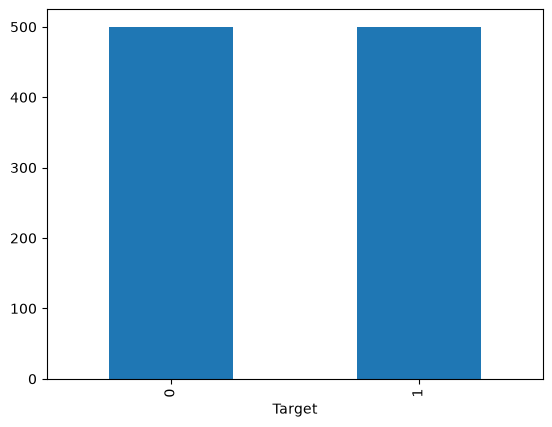

In [88]:
fig , ax= plt.subplots()
Data_df['Target'].value_counts().plot(ax=ax,kind='bar')

### Different plots

<Axes: xlabel='A', ylabel='B'>

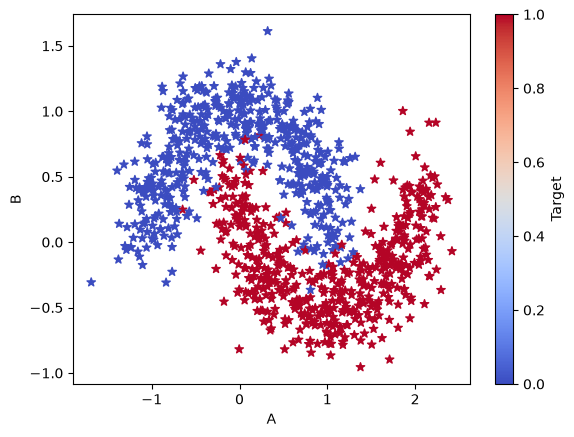

In [89]:
Data_df.plot.scatter('A','B',s=40,marker='*' , c = 'Target',cmap= 'coolwarm')

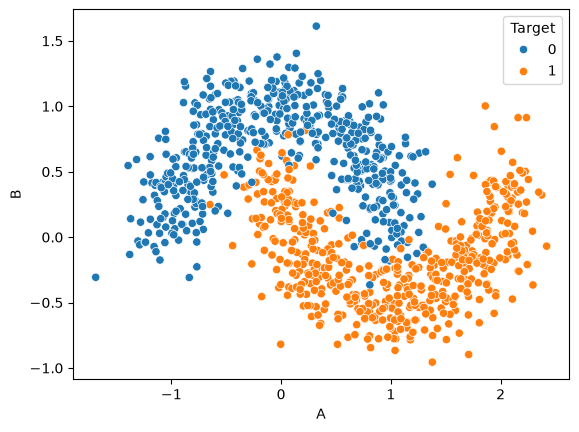

In [90]:

ax = sns.scatterplot(x='A',y='B', data= Data_df, hue='Target')

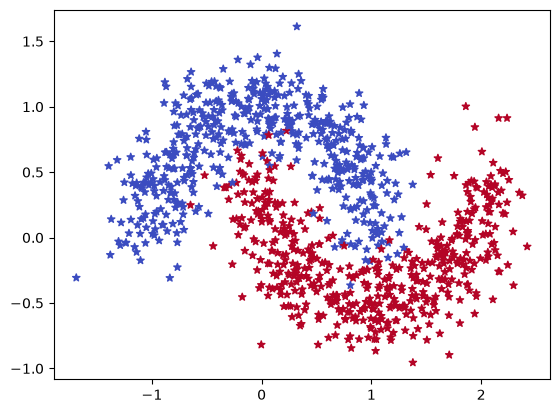

In [91]:
plt.figure()
plt.scatter(X[:,0],X[:,1],s=30,c=y,marker="*",cmap=CMAP)

In [92]:
data_train, data_test = Data_df.to_numpy()[:900], Data_df.to_numpy()[900:]
data_train.shape, data_test.shape

((900, 3), (100, 3))

In [93]:
 def fn_sigmoid(z):
     return 1 / (1+np.exp(-z))

In [94]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [95]:
 def predict(row: np.ndarray, wqts: np.ndarray):
     '''row  : one sample of data
        wqts : weights of the model'''
     z= wqts[0]
     for i in range(len(row)-1):
       z +=wqts[i+1]*row[i]  #Aggregation function
     return fn_sigmoid(z)

In [96]:

weights = np.array([0.1, 2.0, 1.0])
display(Data_df.loc[0])
predict(Data_df.loc[0].values, weights)



A         0.906340
B         0.902676
Target    0.000000
Name: 0, dtype: float64

np.float64(0.9434999754763397)

In [97]:
def train_weights(train: np.ndarray, alpha: float, n_epochs: int) -> tuple[list, np.ndarray]:
    errors = []  # Collect all errors
    weights = rng.random(train.shape[1])
    m = train.shape[0]  # Number of samples

    for epoch in range(n_epochs):  # Fixed indentation (4 spaces)
        sum_error = 0.0
        for row in train:
            a = predict(row, weights)
            
            # Binary Cross-Entropy Loss
            error = -row[-1] * np.log(a) - (1 - row[-1]) * np.log(1 - a)
            dz = a - row[-1]  # dz = a - y
            
            sum_error += error
            
            # Gradient descent weight updates
            weights[0] = weights[0] - alpha * dz  # Bias update
            for i in range(len(row) - 1):
                weights[i + 1] = weights[i + 1] - alpha * dz * row[i]
                
        # Epoch metrics
        errors.append(sum_error / m)
        if epoch % 10 == 0:
            print(f"Epoch {epoch:3d}: Loss = {errors[-1]:.4f}")
            
    return errors, weights


# Run training (verify EPOCHS spelling)
errors, weights = train_weights(data_train, ALPHA, EPOCHES)
display(weights)

Epoch   0: Loss = 0.7639
Epoch  10: Loss = 0.6874
Epoch  20: Loss = 0.6282
Epoch  30: Loss = 0.5823
Epoch  40: Loss = 0.5464
Epoch  50: Loss = 0.5179
Epoch  60: Loss = 0.4948
Epoch  70: Loss = 0.4759
Epoch  80: Loss = 0.4602
Epoch  90: Loss = 0.4468
Epoch 100: Loss = 0.4354
Epoch 110: Loss = 0.4256
Epoch 120: Loss = 0.4169
Epoch 130: Loss = 0.4093
Epoch 140: Loss = 0.4025
Epoch 150: Loss = 0.3964
Epoch 160: Loss = 0.3909
Epoch 170: Loss = 0.3859
Epoch 180: Loss = 0.3814
Epoch 190: Loss = 0.3772
Epoch 200: Loss = 0.3734
Epoch 210: Loss = 0.3698
Epoch 220: Loss = 0.3665
Epoch 230: Loss = 0.3635
Epoch 240: Loss = 0.3606
Epoch 250: Loss = 0.3579
Epoch 260: Loss = 0.3554
Epoch 270: Loss = 0.3530
Epoch 280: Loss = 0.3508
Epoch 290: Loss = 0.3487
Epoch 300: Loss = 0.3467
Epoch 310: Loss = 0.3448
Epoch 320: Loss = 0.3430
Epoch 330: Loss = 0.3413
Epoch 340: Loss = 0.3397
Epoch 350: Loss = 0.3382
Epoch 360: Loss = 0.3367
Epoch 370: Loss = 0.3353
Epoch 380: Loss = 0.3340
Epoch 390: Loss = 0.3327


array([ 0.42987398,  1.17729156, -4.28227621])

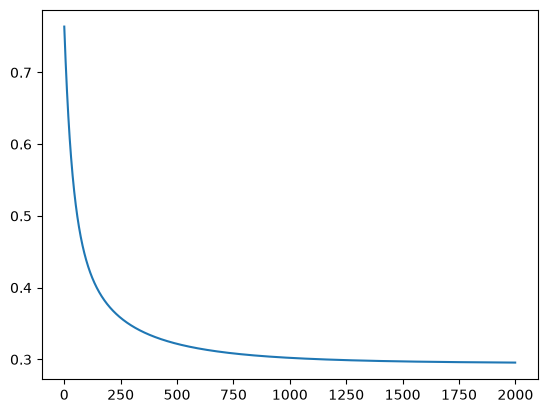

In [98]:
fig , ax = plt.subplots()
ax.plot(errors);

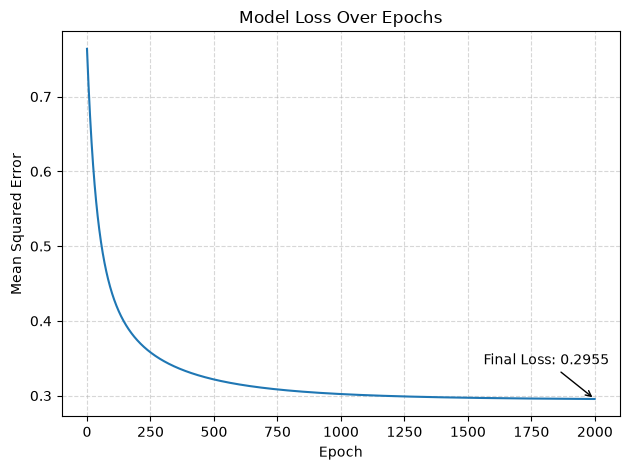

In [99]:
fig, ax = plt.subplots()
# Plot training loss line
ax.plot(errors, color='#1f77b4',  label='Training Loss')
# Titles and axis labels
ax.set_title('Model Loss Over Epochs')
ax.set_xlabel('Epoch')
ax.set_ylabel('Mean Squared Error')
# Subtle grid and clean borders
ax.grid(True, linestyle='--', alpha=0.5)
final_loss = errors[-1]
ax.annotate(f'Final Loss: {final_loss:.4f}', 
            xy=(len(errors)-1, final_loss), 
            xytext=(-80, 25), textcoords='offset points',
            arrowprops=dict(arrowstyle='->')
            )
plt.tight_layout()
plt.show()


In [100]:
predictions = []
for row in data_train:
    a = predict(row, weights)
    y_p = 1 if a >= 0.5 else a<0.5
    predictions.append(y_p)

accuracy_score(data_train[:, -1], predictions)

0.5088888888888888

In [101]:


predictions = []
for row in data_test:
    a = predict(row, weights)
    predictions.append(a>=0.5)

accuracy_score(data_test[:, -1], predictions)

0.9

[[55  3]
 [ 7 35]]


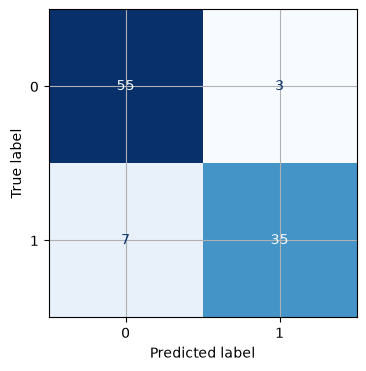

In [102]:

cm = confusion_matrix(data_test[:, -1], predictions) 
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
 
fig , ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.grid()

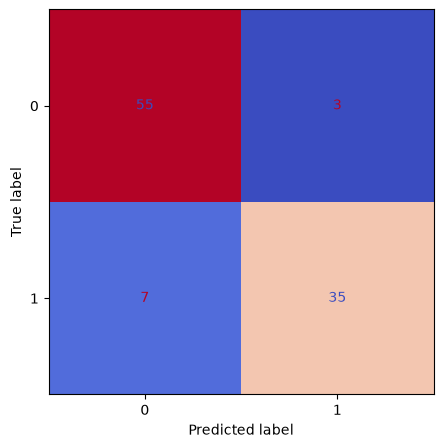

In [103]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=[0, 1]  
)
disp.plot(ax=ax, cmap=CMAP, colorbar=False)
# plt.grid()
plt.show()

In [104]:
def plot_decision_boundary(x_tr,x_ts,wts):
    fig , ax = plt.subplots()
    dm=0.01
    margine = 10*dm
    x_min , x_max = x_tr[:,0].min() - margine,x_tr[:,0].max() - margine
    y_min , y_max = x_tr[:,1].min() - margine,x_tr[:,0].max() - margine
    xx,yy = np.meshgrid(np.arange(x_min , x_max,dm),np.arange(y_min , y_max,dm))
    XX = np.c_[xx.ravel(),yy.ravel()]
    XX = np.hstack ((XX,np.ones((XX.shape[0],1))))
    y_pred =[]
    for row in XX:
        a=predict(row,wts)
        y_p= 1 if a>= 0.5 else 0
        y_pred.append(a)
    Z = np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx,yy,Z,cmap= plt.cm.Paired , alpha = 0.6)
    ax.scatter(x_tr[:,0],x_tr[:,1],c=x_tr[:,2], s =30 , edgecolors='k', cmap= plt.cm.seismic)

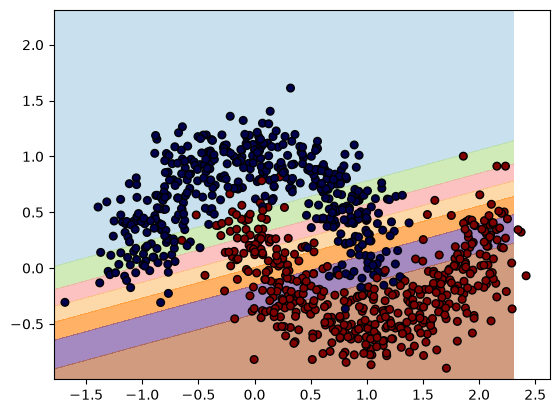

In [105]:
plot_decision_boundary(data_train,data_test, weights)